## Dynamic Vessel Status: Heading, Course, Speed, and Manoeuvring (Flag 10)

### Dataset Overview
This one-vessel AIS-like case retains dynamic fields available in Danish AIS: timestamp, position, SOG, COG, heading, ROT, and navigational status. It contains one continuous trajectory whose middle segment has a sustained heading–COG discrepancy, frequent course changes, slower speed, and elevated turning intensity.

The notebook exposes a primary table and a supporting table (`vessel_attributes.csv`).

Goal: Investigate the dynamic status of the vessel over time from its trajectory, with particular attention to changing movement dynamics.

Role: Maritime trajectory analyst


Category: single-vessel dynamic navigation status over time

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessel_attributes.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: When does the vessel's heading depart from its course over ground, how large is the discrepancy, and when does it realign?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

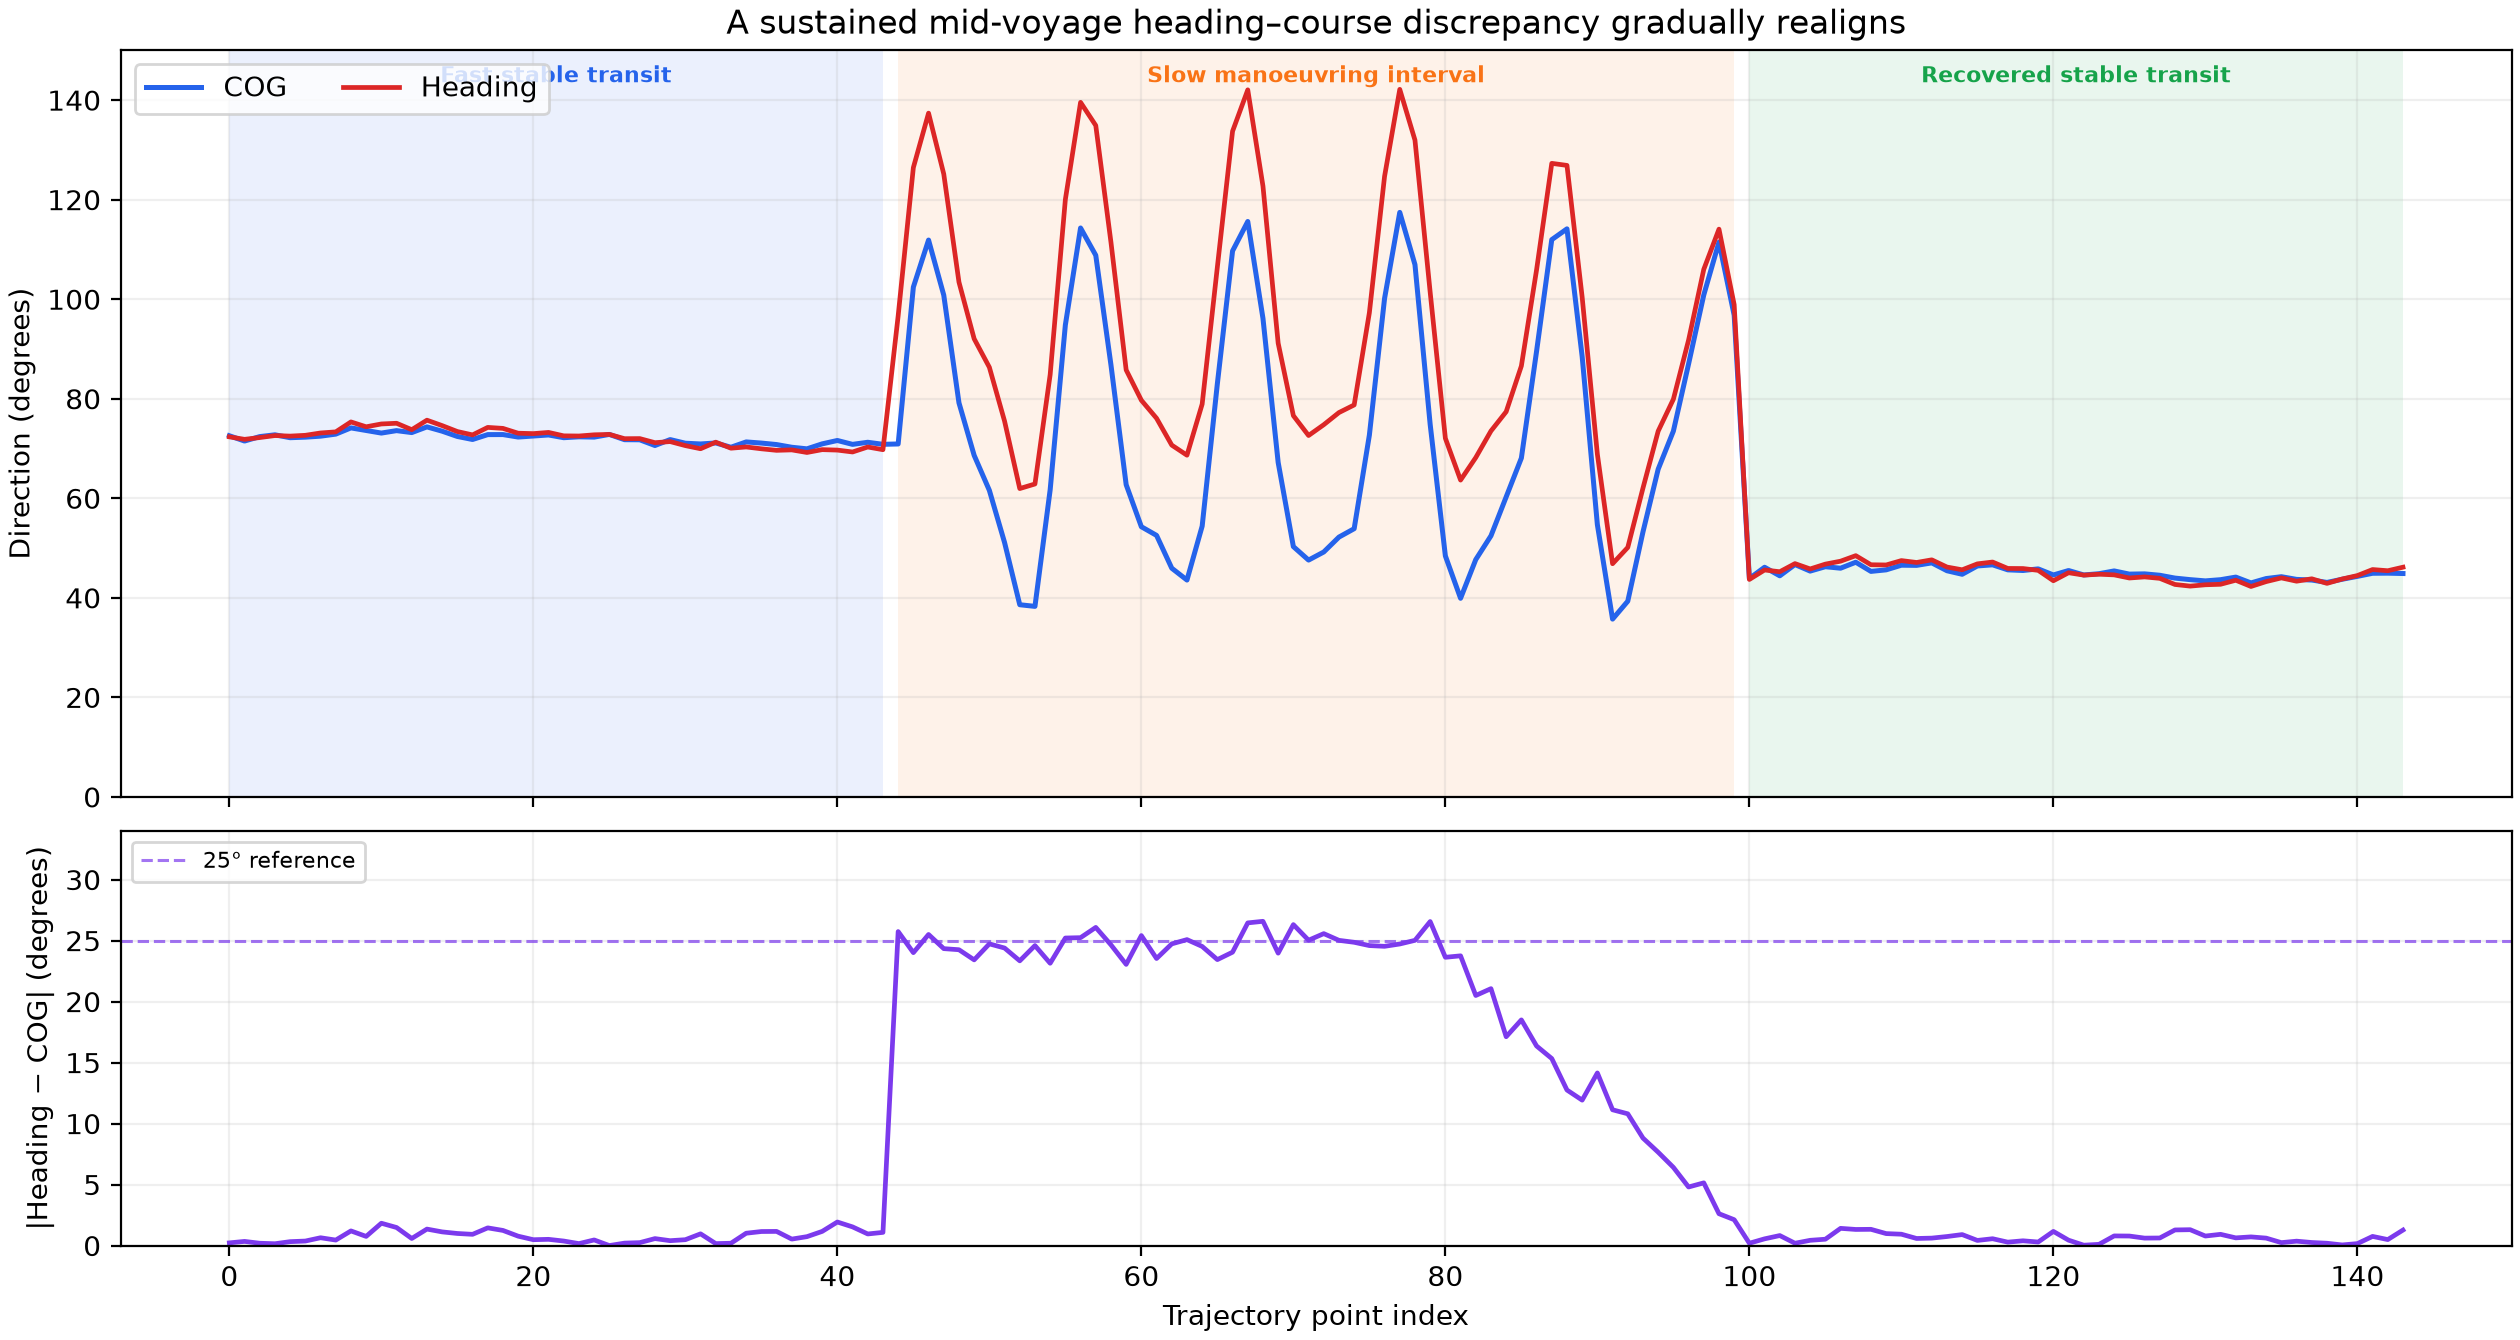

In [ ]:
import pandas as pd
points = pd.read_csv(dataset_path).sort_values('point_index')
def circular_gap(a, b): return abs((a - b + 180) % 360 - 180)
points['heading_cog_gap_deg'] = circular_gap(points['heading'], points['cog'])
print(points[['point_index', 'heading_cog_gap_deg']].describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/heading_course_discrepancy_over_time.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "heading_course_alignment_time_series",
  "insight": "The vessel develops a sustained heading–course discrepancy during the middle portion of its trajectory before gradually realigning.",
  "insight_value": {
    "sustained_discrepancy_points": 36,
    "typical_discrepancy_deg": 25,
    "realignment_start_point": 80
  },
  "plot": {
    "plot_type": "dual_direction_time_series",
    "title": "Heading–Course Discrepancy over Time",
    "file": "visualizations/heading_course_discrepancy_over_time.png",
    "description": "COG and heading are plotted directly, with their absolute difference shown below across the three voyage phases."
  },
  "question": "When does the vessel's heading depart from its course over ground, how large is the discrepancy, and when does it realign?",
  "code": "import pandas as pd\npoints = pd.read_csv(dataset_path).sort_values('point_index')\ndef circular_gap(a, b): return abs((a - b + 180) % 360 - 180)\npoints['heading_cog_gap_deg'] = circular_gap(points['heading'], points['cog'])\nprint(points[['point_index', 'heading_cog_gap_deg']].describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "heading",
    "course_over_ground"
  ]
}

### **Question 2**: How does the vessel move from nearly straight navigation into intensive manoeuvring, and when does the heading–COG relationship return to stable alignment?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

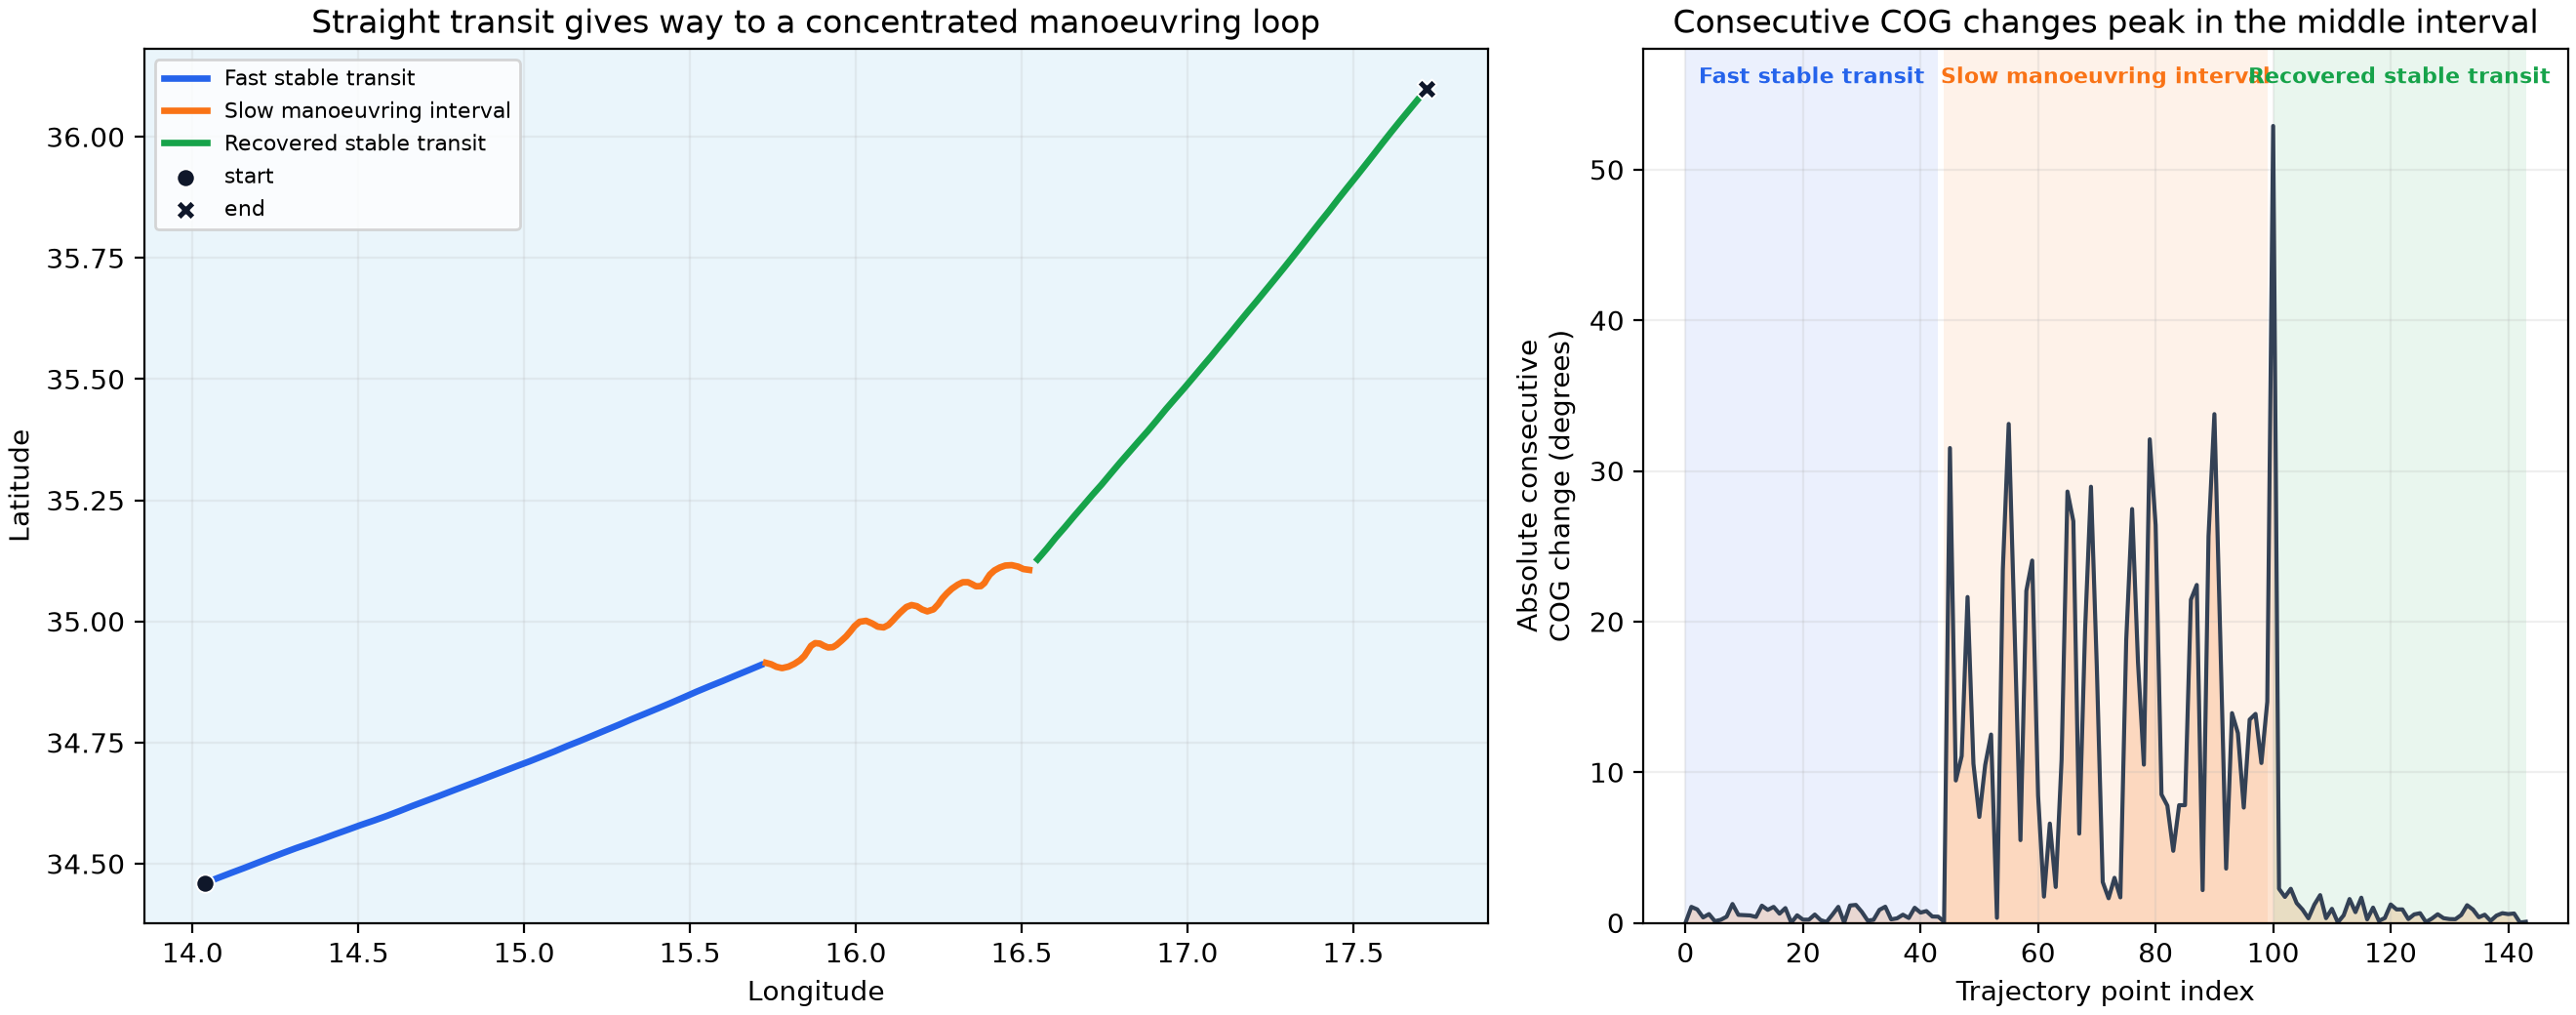

In [ ]:
import pandas as pd
points = pd.read_csv(dataset_path).sort_values('point_index')
# Compute circular absolute differences between consecutive COG values and compare their distributions across contiguous time intervals.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/manoeuvring_course_change_pattern.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "time_ordered_manoeuvring_structure",
  "insight": "The vessel transitions from nearly straight navigation to a middle period of intensive manoeuvring with frequent course changes, then returns to stable alignment between heading and COG later in the trajectory.",
  "insight_value": {
    "stable_start_points": [
      0,
      43
    ],
    "intensive_manoeuvring_points": [
      44,
      99
    ],
    "stable_recovery_points": [
      100,
      143
    ]
  },
  "plot": {
    "plot_type": "trajectory_map_and_course_change_series",
    "title": "Manoeuvring Course-Change Pattern",
    "file": "visualizations/manoeuvring_course_change_pattern.png",
    "description": "The map isolates the curving middle path; the time-series panel shows its repeated consecutive COG changes."
  },
  "question": "How does the vessel move from nearly straight navigation into intensive manoeuvring, and when does the heading–COG relationship return to stable alignment?",
  "code": "import pandas as pd\npoints = pd.read_csv(dataset_path).sort_values('point_index')\n# Compute circular absolute differences between consecutive COG values and compare their distributions across contiguous time intervals.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "heading",
    "course_over_ground",
    "gps_position"
  ]
}

### **Question 3**: How do speed and turning intensity change together over the voyage, and which interval is most manoeuvre-intensive?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

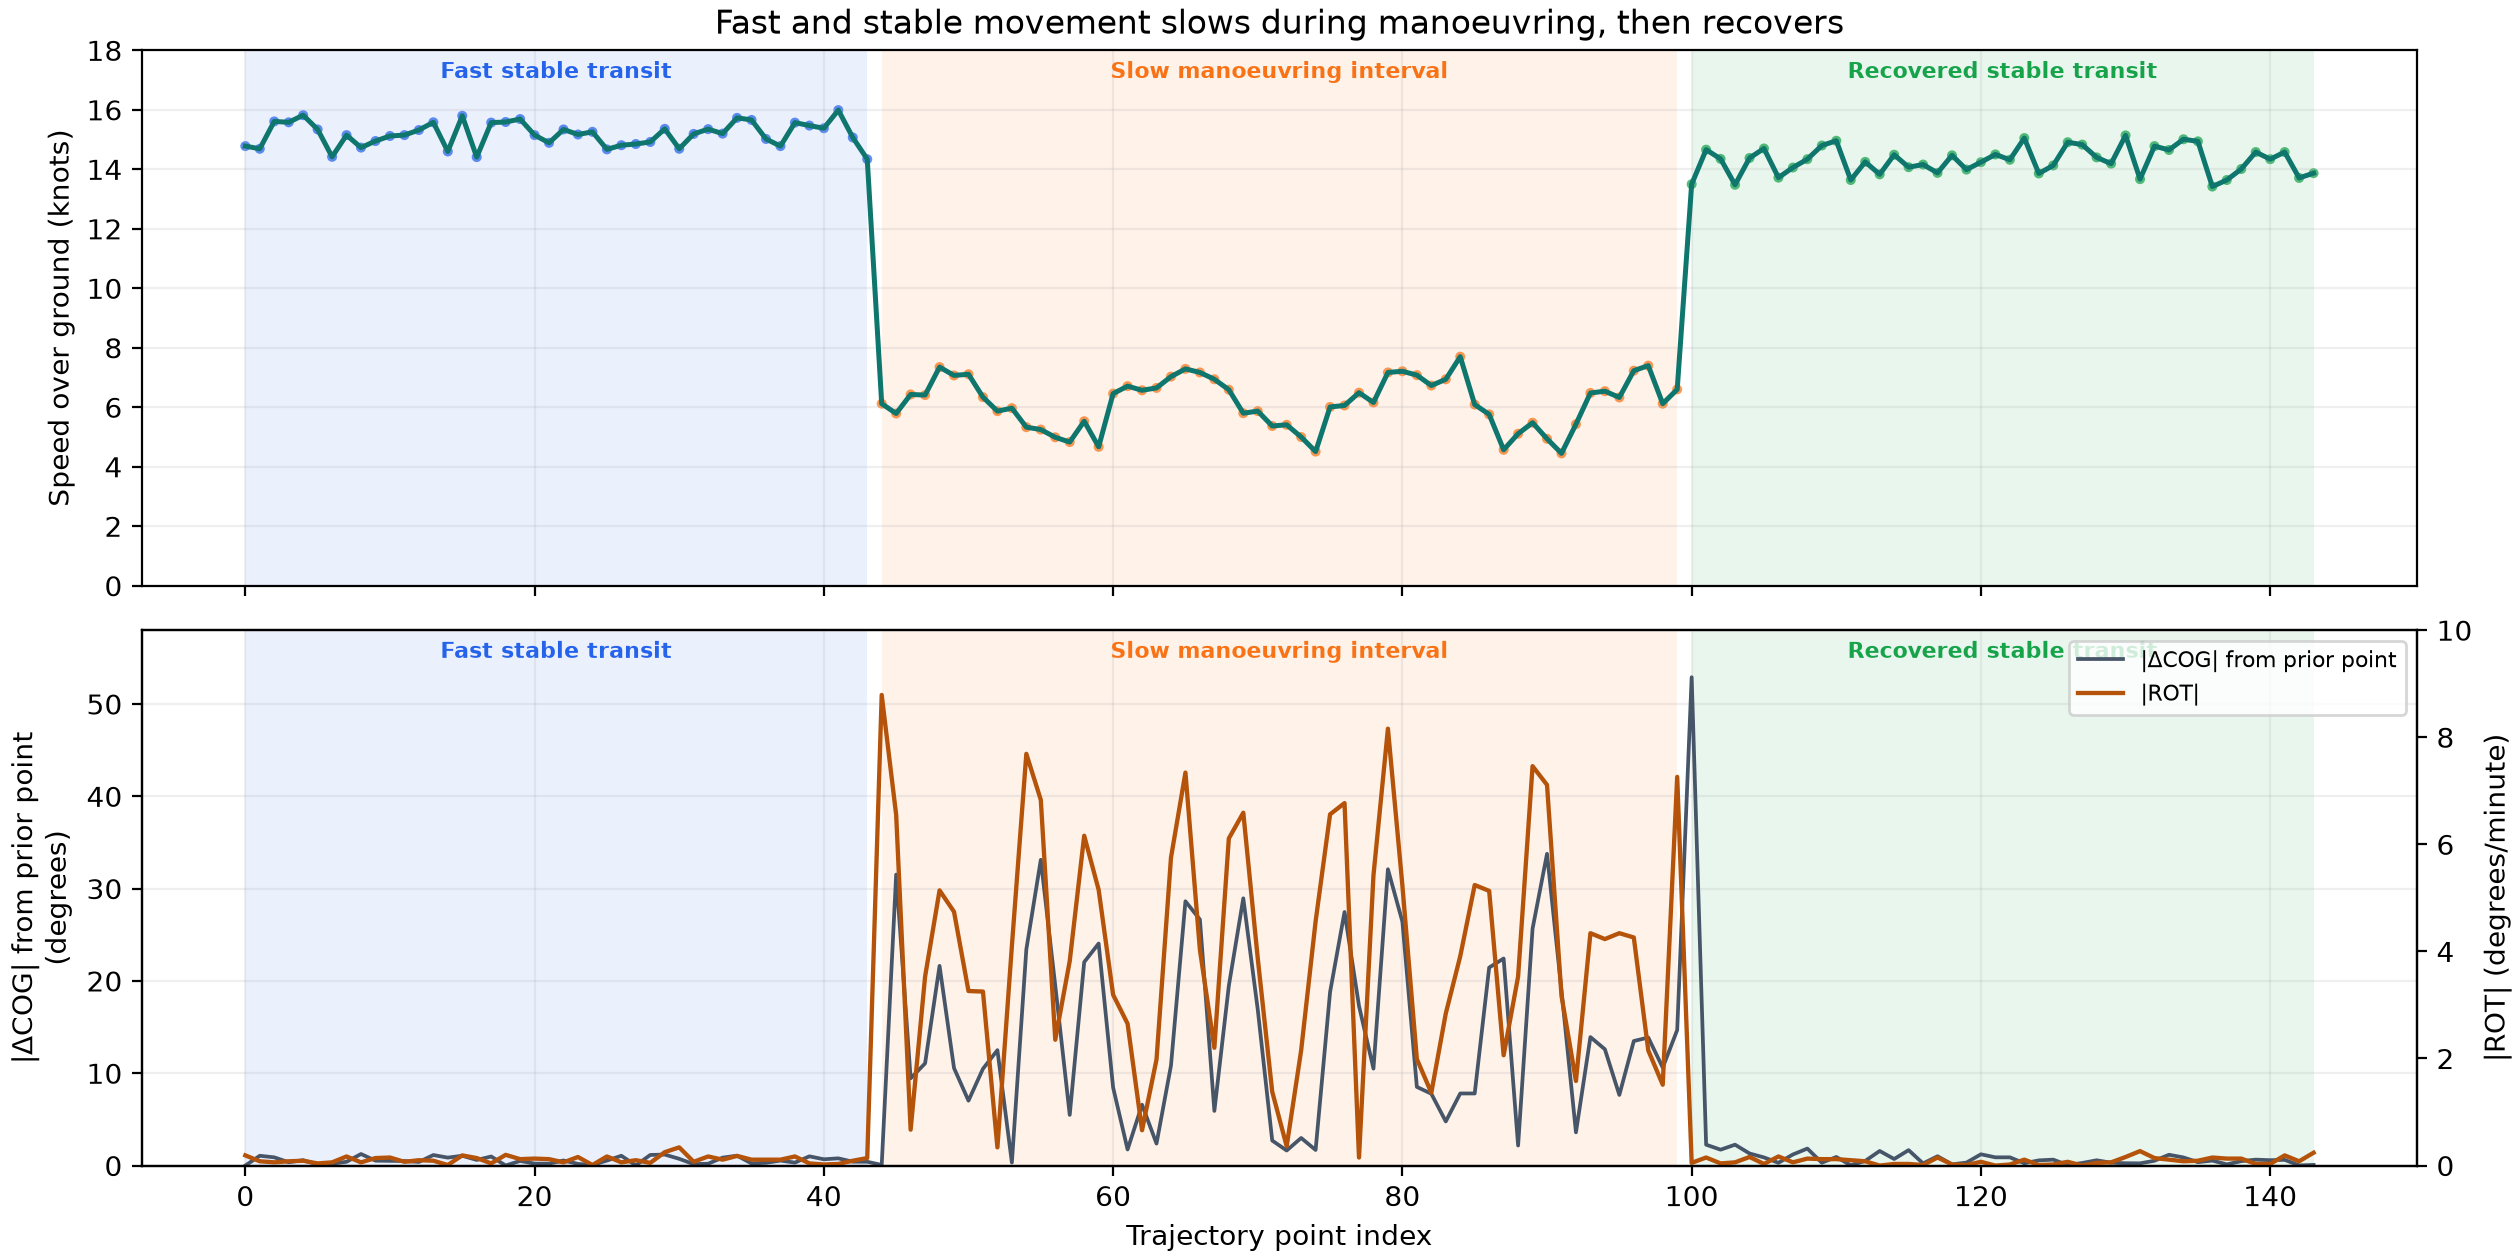

In [ ]:
import pandas as pd
points = pd.read_csv(dataset_path).sort_values('point_index')
print(points[['sog_knots', 'rot_deg_per_min', 'cog']].describe())
# Compare speed and |ROT| with the circular change in COG between consecutive points for each contiguous phase.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_and_manoeuvring_intensity.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_and_turning_intensity_phase_transition",
  "insight": "The vessel shifts from fast, directionally stable navigation into a slower and more manoeuvre-intensive phase, before resuming faster and steadier movement later in the trajectory.",
  "insight_value": {
    "fast_stable_speed_knots": "about 14–15",
    "middle_phase_speed_knots": "about 5–7",
    "middle_phase_turning_signals": [
      "higher |ROT|",
      "larger consecutive COG changes"
    ]
  },
  "plot": {
    "plot_type": "speed_and_turning_intensity_time_series",
    "title": "Speed and Manoeuvring Intensity",
    "file": "visualizations/speed_and_manoeuvring_intensity.png",
    "description": "Speed falls as both ROT magnitude and point-to-point COG changes rise, then the three measures return to a stable transit pattern."
  },
  "question": "How do speed and turning intensity change together over the voyage, and which interval is most manoeuvre-intensive?",
  "code": "import pandas as pd\npoints = pd.read_csv(dataset_path).sort_values('point_index')\nprint(points[['sog_knots', 'rot_deg_per_min', 'cog']].describe())\n# Compare speed and |ROT| with the circular change in COG between consecutive points for each contiguous phase.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "point_speed",
    "course_over_ground",
    "rate_of_turn"
  ]
}

### Summary of Findings (Flag 10)

The vessel is dynamically stable at the beginning and end of the voyage, but its middle interval has a sustained heading–course offset, slower speed, and frequent turning. These signals identify one concentrated manoeuvring phase followed by a gradual return to stable transit.